# DATA UNDERSTANDING & EDA


### 1. Nạp dữ liệu, kiểm tra cấu trúc và phân bố nhãn

In [11]:
from IPython.display import display
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
SRC = ROOT / 'data' / 'raw' / 'RT_IOT2022.csv'
if not SRC.exists():
    raise FileNotFoundError(f'Chưa có dữ liệu')
OUT=ROOT/'reports'/'01_data_understanding_eda'
FIG=OUT/'figures'; TAB=OUT/'tables'; FIG.mkdir(exist_ok=True); TAB.mkdir(exist_ok=True)
df=pd.read_csv(SRC,low_memory=False)
target='Attack_type'; idx='Unnamed: 0'
assert target in df.columns
labels=df[target].value_counts()
labels.rename_axis('label').reset_index(name='count').assign(percentage=lambda x: x['count']/len(df)*100).to_csv(TAB/'class_distribution.csv',index=False)
col_info=pd.DataFrame({'column':df.columns,'dtype':df.dtypes.astype(str).values,'missing':df.isna().sum().values,'unique':df.nunique(dropna=False).values})
col_info.to_csv(TAB/'column_dictionary.csv',index=False)
num=df.select_dtypes(include='number'); nums=num.drop(columns=[idx],errors='ignore')
num.describe(percentiles=[.01,.25,.5,.75,.95,.99]).T.to_csv(TAB/'numeric_summary.csv')
for c in ['proto','service']:
    if c in df: df[c].fillna('<MISSING>').value_counts().rename_axis(c).reset_index(name='count').to_csv(TAB/f'{c}_counts.csv',index=False)
print("Kích thước dữ liệu:", df.shape)
print("Kiểu dữ liệu:\n", df.dtypes.value_counts())

Kích thước dữ liệu: (123117, 85)
Kiểu dữ liệu:
 float64    56
int64      26
object      3
Name: count, dtype: int64


In [12]:
display(df.head(5))
display(labels.rename_axis('label').reset_index(name='count'))
display(col_info.head(15))

,Unnamed: 0,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,...,0.0,2.972918e+07,2.972918e+07,2.972918e+07,2.972918e+07,0.0,64240,26847,502,MQTT_Publish
1,1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,...,0.0,2.985528e+07,2.985528e+07,2.985528e+07,2.985528e+07,0.0,64240,26847,502,MQTT_Publish
2,2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,...,0.0,2.984215e+07,2.984215e+07,2.984215e+07,2.984215e+07,0.0,64240,26847,502,MQTT_Publish
3,3,60893,1883,tcp,mqtt,31.961063,9,5,3,3,...,0.0,2.991377e+07,2.991377e+07,2.991377e+07,2.991377e+07,0.0,64240,26847,502,MQTT_Publish
4,4,51087,1883,tcp,mqtt,31.902362,9,5,3,3,...,0.0,2.981470e+07,2.981470e+07,2.981470e+07,2.981470e+07,0.0,64240,26847,502,MQTT_Publish


,label,count
0,DOS_SYN_Hping,94659
1,Thing_Speak,8108
2,ARP_poisioning,7750
3,MQTT_Publish,4146
4,NMAP_UDP_SCAN,2590
5,NMAP_XMAS_TREE_SCAN,2010
6,NMAP_OS_DETECTION,2000
7,NMAP_TCP_scan,1002
8,DDOS_Slowloris,534
9,Wipro_bulb,253


,column,dtype,missing,unique
0,Unnamed: 0,int64,0,94659
1,id.orig_p,int64,0,65478
2,id.resp_p,int64,0,1809
3,proto,object,0,3
4,service,object,0,10
5,flow_duration,float64,0,16383
6,fwd_pkts_tot,int64,0,163
7,bwd_pkts_tot,int64,0,172
8,fwd_data_pkts_tot,int64,0,116
9,bwd_data_pkts_tot,int64,0,154


### 2. Trùng lặp, xung đột nhãn và giá trị vô cực

In [13]:
# Đếm bản ghi trùng chính xác sau khi bỏ cột index do quá trình xuất dữ liệu tạo ra.
base=df.drop(columns=[idx],errors='ignore')
duplicates=int(base.duplicated().sum())
feature_cols=[c for c in base.columns if c!=target]
# Dùng hash để lọc nhanh các nhóm nghi ngờ, sau đó đối chiếu chính xác để tránh kết luận sai do hash collision.
h=pd.util.hash_pandas_object(base[feature_cols],index=False)
conflict_hashes=base.groupby(h,sort=False)[target].nunique()
conflicting_hashes=conflict_hashes[conflict_hashes>1].index
conflicts=base.loc[h.isin(conflicting_hashes)].copy()
# Groupby lại trên toàn bộ đặc trưng để xác nhận kết quả và loại trừ hash collision.
conflict_groups=conflicts.groupby(feature_cols,dropna=False)[target].nunique()
conflict_count=int((conflict_groups>1).sum())
conflict_rows=int(conflicts.shape[0])
conflicts[[target]+feature_cols[:5]].to_csv(TAB/'conflicting_label_examples.csv',index=False)
# Đếm các giá trị NaN hoặc vô cực trong các cột số để đánh giá chất lượng dữ liệu.
inf_counts=np.isinf(num.to_numpy(dtype='float64')).sum(axis=0)
quality=pd.DataFrame({'column':num.columns,'inf_count':inf_counts})
quality.to_csv(TAB/'nonfinite_counts.csv',index=False)
print("Số dòng trùng:", duplicates, "| Số nhóm xung đột nhãn:", conflict_count, "| Số giá trị vô cực:", int(inf_counts.sum()))
display(quality.loc[quality.inf_count > 0].head(10))

Số dòng trùng: 5195 | Số nhóm xung đột nhãn: 6 | Số giá trị vô cực: 0


,column,inf_count


### 3. Tương quan Spearman

In [14]:
# Chỉ tính tương quan trên biến số, bỏ cột index và cột hằng vì chúng không mang thông tin phân biệt.
vary=nums.loc[:,nums.nunique(dropna=False)>1]
corr=vary.corr(method='spearman')
# Chỉ giữ một chiều của mỗi cặp biến và loại đường chéo để bảng tương quan không bị trùng.
pairs=[]
for i,c in enumerate(corr.columns):
    for j in range(i):
        v=corr.iat[i,j]
        if np.isfinite(v): pairs.append((corr.columns[j],c,float(v),abs(float(v))))
pd.DataFrame(sorted(pairs,key=lambda x:x[3],reverse=True)[:40],columns=['feature_a','feature_b','spearman_r','abs_r']).to_csv(TAB/'top_spearman_pairs.csv',index=False)
display(pd.read_csv(TAB/"top_spearman_pairs.csv").head(10))

,feature_a,feature_b,spearman_r,abs_r
0,fwd_bulk_bytes,fwd_bulk_rate,0.999999,0.999999
1,fwd_bulk_bytes,fwd_bulk_packets,0.999999,0.999999
2,fwd_bulk_packets,fwd_bulk_rate,0.999999,0.999999
3,active.max,active.tot,0.999994,0.999994
4,idle.max,idle.avg,0.999994,0.999994
5,bwd_bulk_bytes,bwd_bulk_packets,0.999990,0.999990
6,idle.min,idle.avg,0.999981,0.999981
7,bwd_bulk_bytes,bwd_bulk_rate,0.999979,0.999979
8,bwd_bulk_packets,bwd_bulk_rate,0.999970,0.999970
9,fwd_pkts_per_sec,flow_pkts_per_sec,0.999963,0.999963


In [15]:
display(pd.read_csv(TAB/'top_spearman_pairs.csv').head(15))

,feature_a,feature_b,spearman_r,abs_r
0,fwd_bulk_bytes,fwd_bulk_rate,0.999999,0.999999
1,fwd_bulk_bytes,fwd_bulk_packets,0.999999,0.999999
2,fwd_bulk_packets,fwd_bulk_rate,0.999999,0.999999
3,active.max,active.tot,0.999994,0.999994
4,idle.max,idle.avg,0.999994,0.999994
5,bwd_bulk_bytes,bwd_bulk_packets,0.999990,0.999990
6,idle.min,idle.avg,0.999981,0.999981
7,bwd_bulk_bytes,bwd_bulk_rate,0.999979,0.999979
8,bwd_bulk_packets,bwd_bulk_rate,0.999970,0.999970
9,fwd_pkts_per_sec,flow_pkts_per_sec,0.999963,0.999963


### 4. Trực quan hóa phân bố, giao thức và đặc trưng

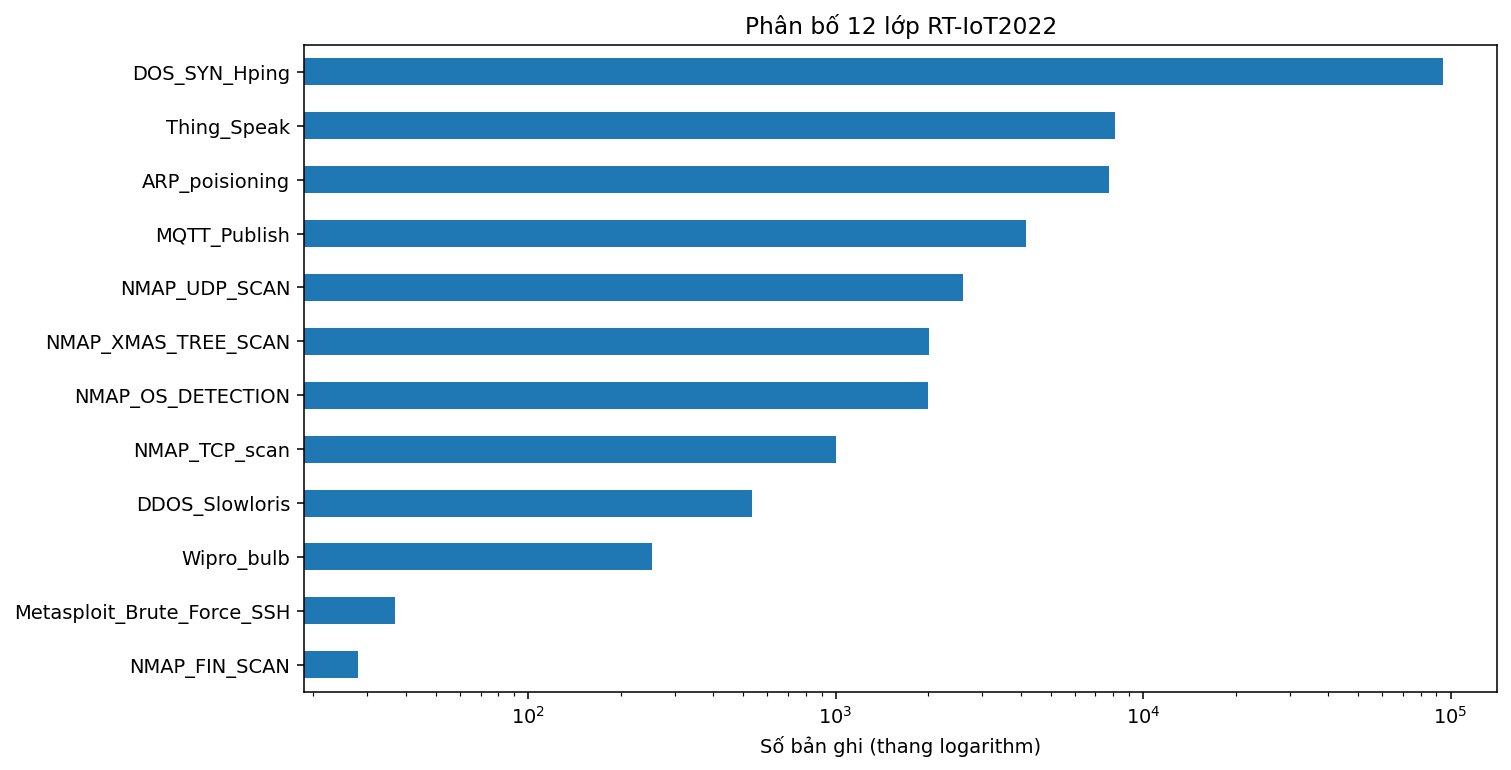

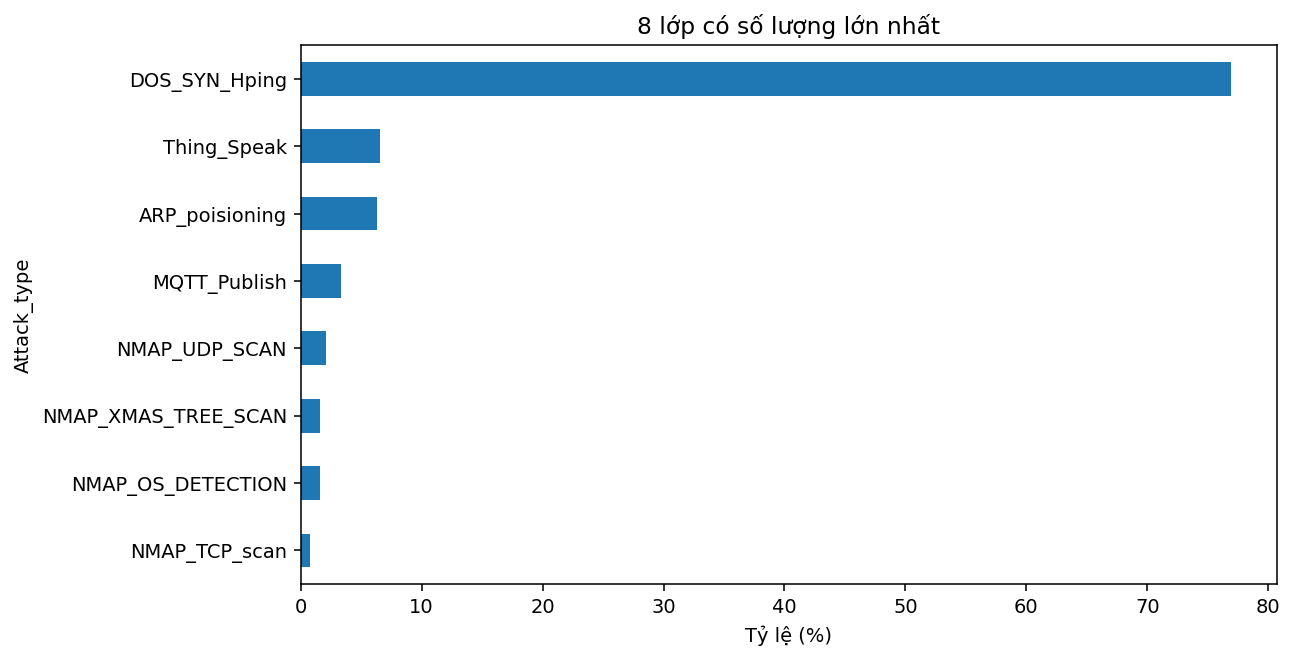

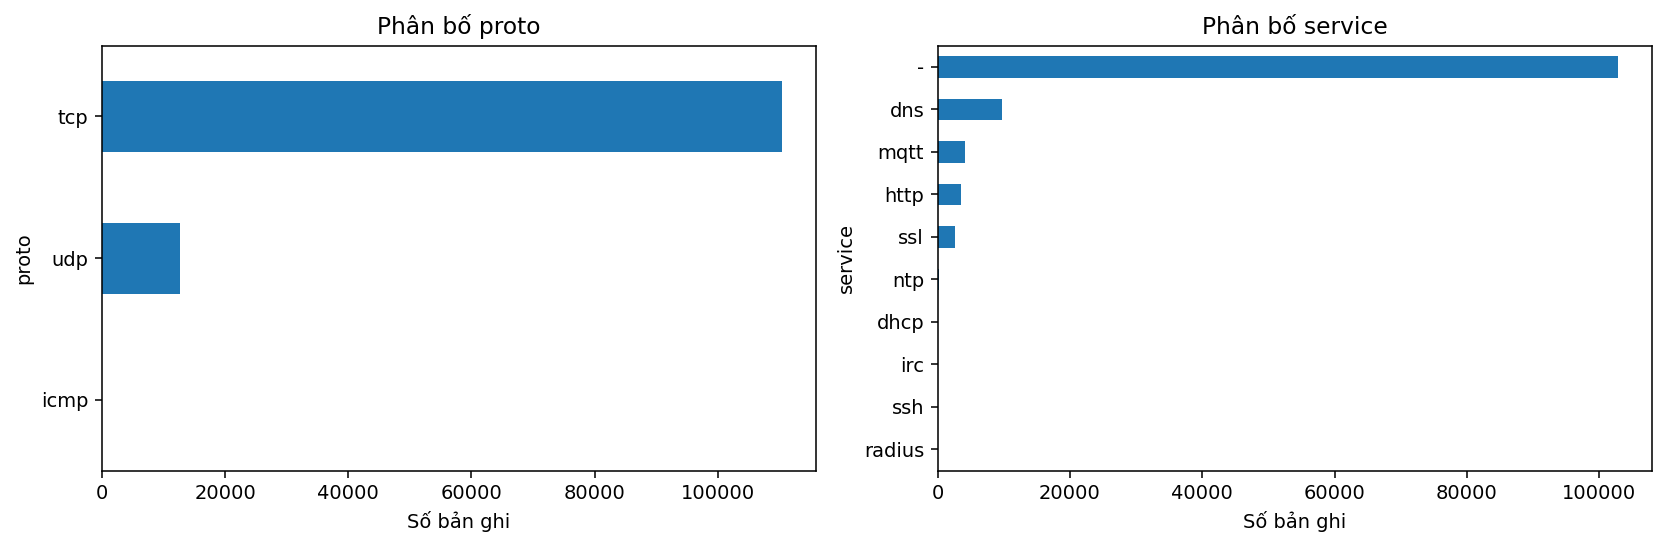

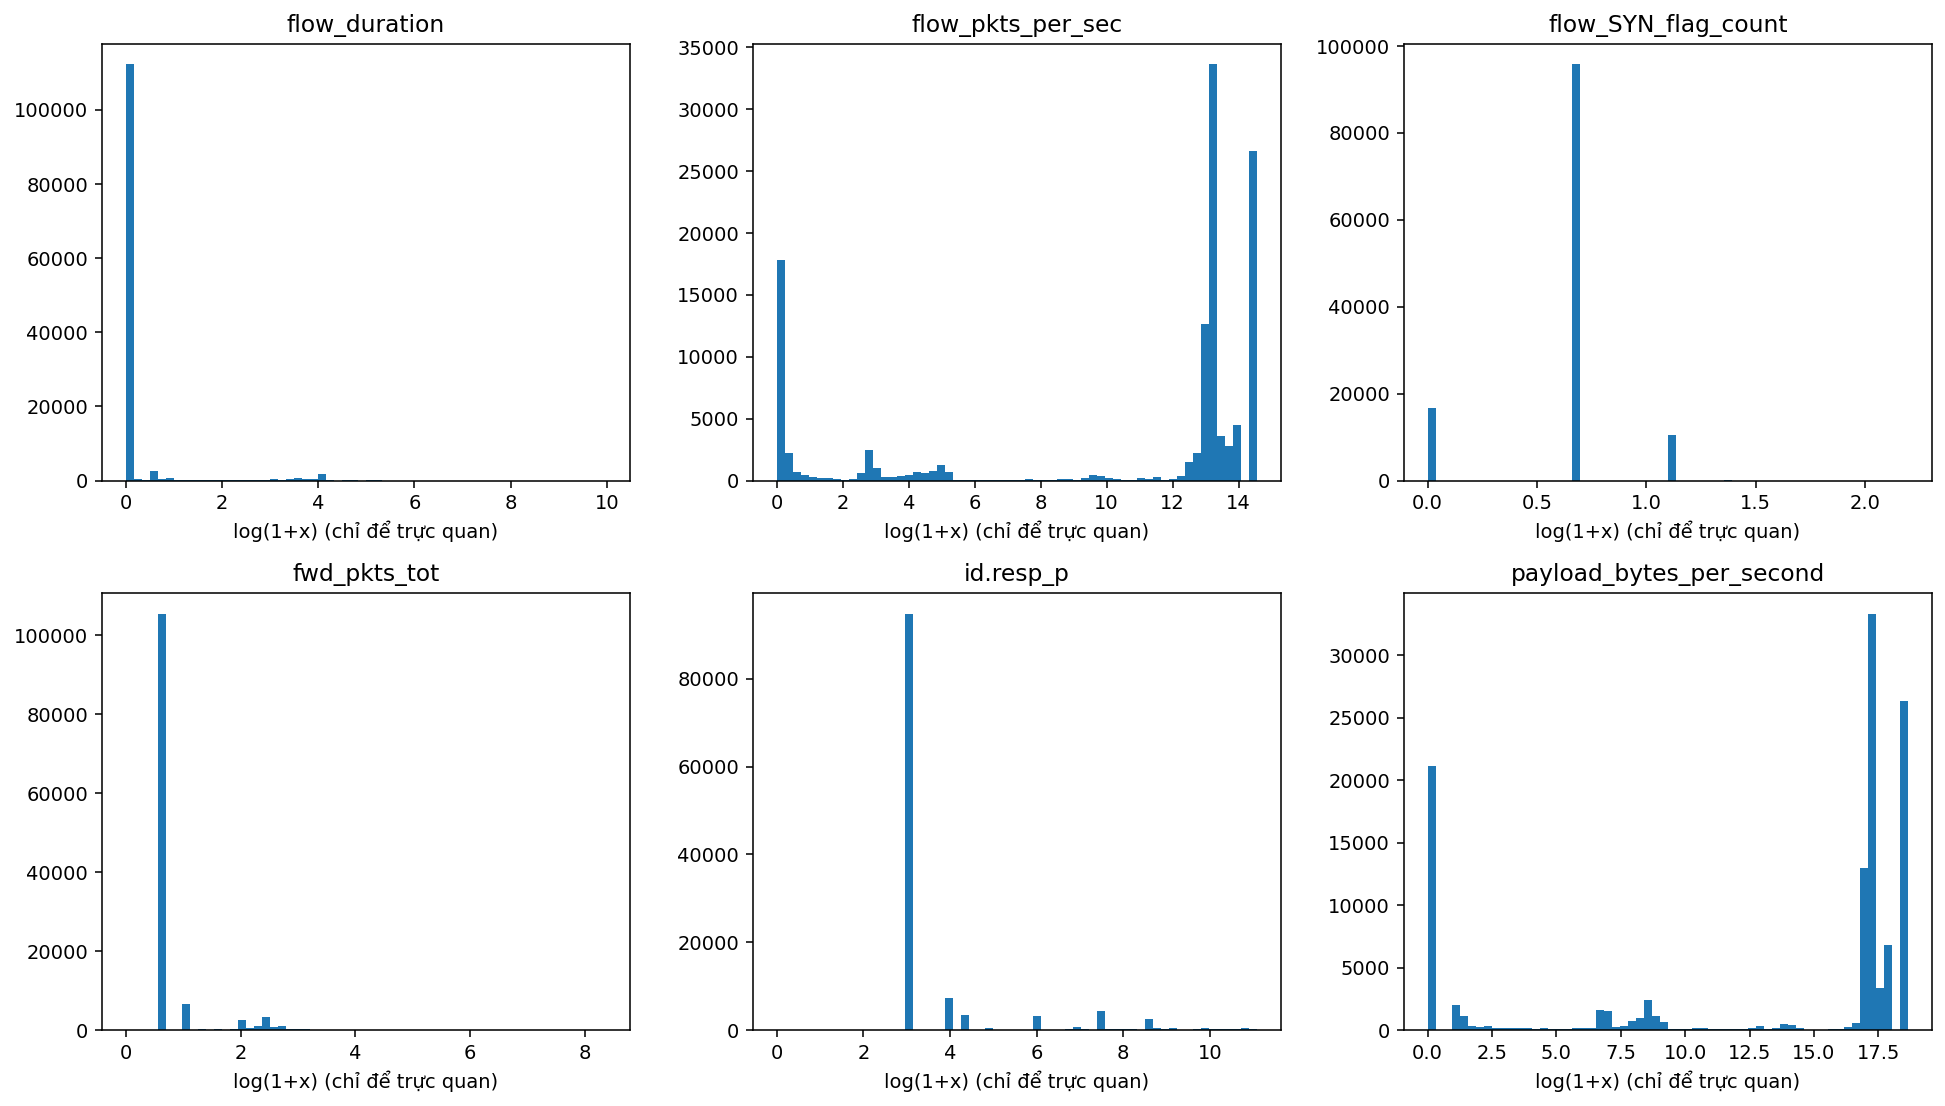

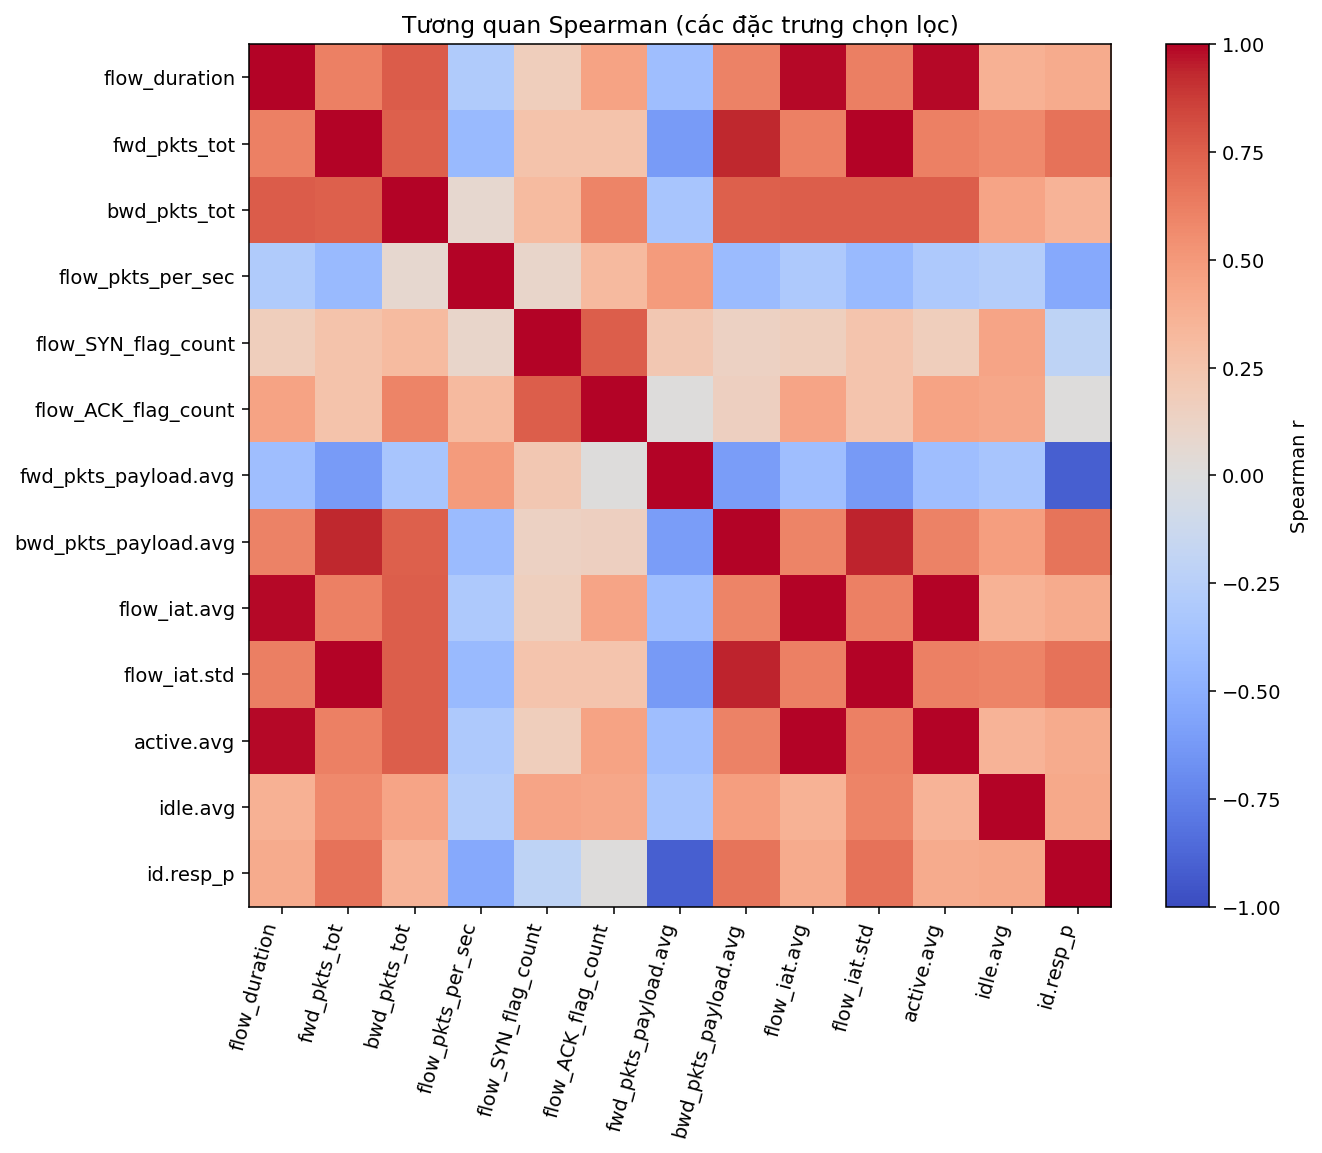

In [16]:
plt.rcParams.update({'font.size':10,'figure.dpi':140,'savefig.bbox':'tight'})
fig,ax=plt.subplots(figsize=(11,6)); labels.sort_values().plot.barh(ax=ax); ax.set_xscale('log'); ax.set_xlabel('Số bản ghi (thang logarithm)');ax.set_ylabel('');ax.set_title('Phân bố 12 lớp RT-IoT2022');fig.savefig(FIG/'01_class_distribution_log.png');plt.close(fig)
fig,ax=plt.subplots(figsize=(9,5));(labels/len(df)*100).head(8).sort_values().plot.barh(ax=ax);ax.set_xlabel('Tỷ lệ (%)');ax.set_title('8 lớp có số lượng lớn nhất');fig.savefig(FIG/'02_class_percentage.png');plt.close(fig)
fig,axs=plt.subplots(1,2,figsize=(12,4))
for ax,c in zip(axs,['proto','service']):
    if c in df:
        counts=df[c].fillna('<MISSING>').value_counts().head(12)
        counts.sort_values().plot.barh(ax=ax)
        ax.set_title(f'Phân bố {c}');ax.set_xlabel('Số bản ghi')
fig.tight_layout();fig.savefig(FIG/'03_categorical_distributions.png');plt.close(fig)
selected=[c for c in ['flow_duration','flow_pkts_per_sec','flow_SYN_flag_count','fwd_pkts_tot','id.resp_p','payload_bytes_per_second'] if c in df]
fig,axs=plt.subplots(2,3,figsize=(14,8))
for ax,c in zip(axs.flat,selected):
    s=pd.to_numeric(df[c],errors='coerce').dropna()
    if (s>=0).all(): s=np.log1p(s);ax.set_xlabel('log(1+x) (chỉ để trực quan)')
    ax.hist(s,bins=60);ax.set_title(c)
for ax in list(axs.flat)[len(selected):]:ax.axis('off')
fig.tight_layout();fig.savefig(FIG/'04_numeric_distributions.png');plt.close(fig)
heatcols=[c for c in ['flow_duration','fwd_pkts_tot','bwd_pkts_tot','flow_pkts_per_sec','flow_SYN_flag_count','flow_ACK_flag_count','fwd_pkts_payload.avg','bwd_pkts_payload.avg','flow_iat.avg','flow_iat.std','active.avg','idle.avg','id.resp_p'] if c in corr.columns]
fig,ax=plt.subplots(figsize=(10,8));heat=corr.loc[heatcols,heatcols];im=ax.imshow(heat,vmin=-1,vmax=1,cmap='coolwarm');ax.set_xticks(range(len(heatcols)),heatcols,rotation=75,ha='right');ax.set_yticks(range(len(heatcols)),heatcols);fig.colorbar(im,ax=ax,label='Spearman r');ax.set_title('Tương quan Spearman (các đặc trưng chọn lọc)');fig.savefig(FIG/'05_spearman_heatmap.png');plt.close(fig)
from IPython.display import Image
for filename in ["01_class_distribution_log.png", "02_class_percentage.png", "03_categorical_distributions.png", "04_numeric_distributions.png", "05_spearman_heatmap.png"]:
    display(Image(filename=str(FIG / filename)))

### 5. Trung vị theo lớp và biểu đồ

,Attack_type,flow_duration,flow_pkts_per_sec,flow_SYN_flag_count,fwd_pkts_tot,id.resp_p
0,ARP_poisioning,0.000637,6.465031,0.0,2.0,443.0
1,DDOS_Slowloris,20.088963,0.649753,2.0,6.0,80.0
2,DOS_SYN_Hping,0.000003,493447.529412,1.0,1.0,21.0
3,MQTT_Publish,44.067645,0.349426,2.0,10.0,1883.0
4,Metasploit_Brute_Force_SSH,2.030317,13.343112,2.0,14.0,22.0
5,NMAP_FIN_SCAN,0.000000,0.000000,0.0,1.0,22.0
6,NMAP_OS_DETECTION,0.000006,335544.320000,0.0,1.0,3720.0
7,NMAP_TCP_scan,0.000004,524288.000000,1.0,1.0,3751.5
8,NMAP_UDP_SCAN,0.000000,0.000000,0.0,1.0,19075.0
9,NMAP_XMAS_TREE_SCAN,0.000007,289262.344828,0.0,1.0,3690.0


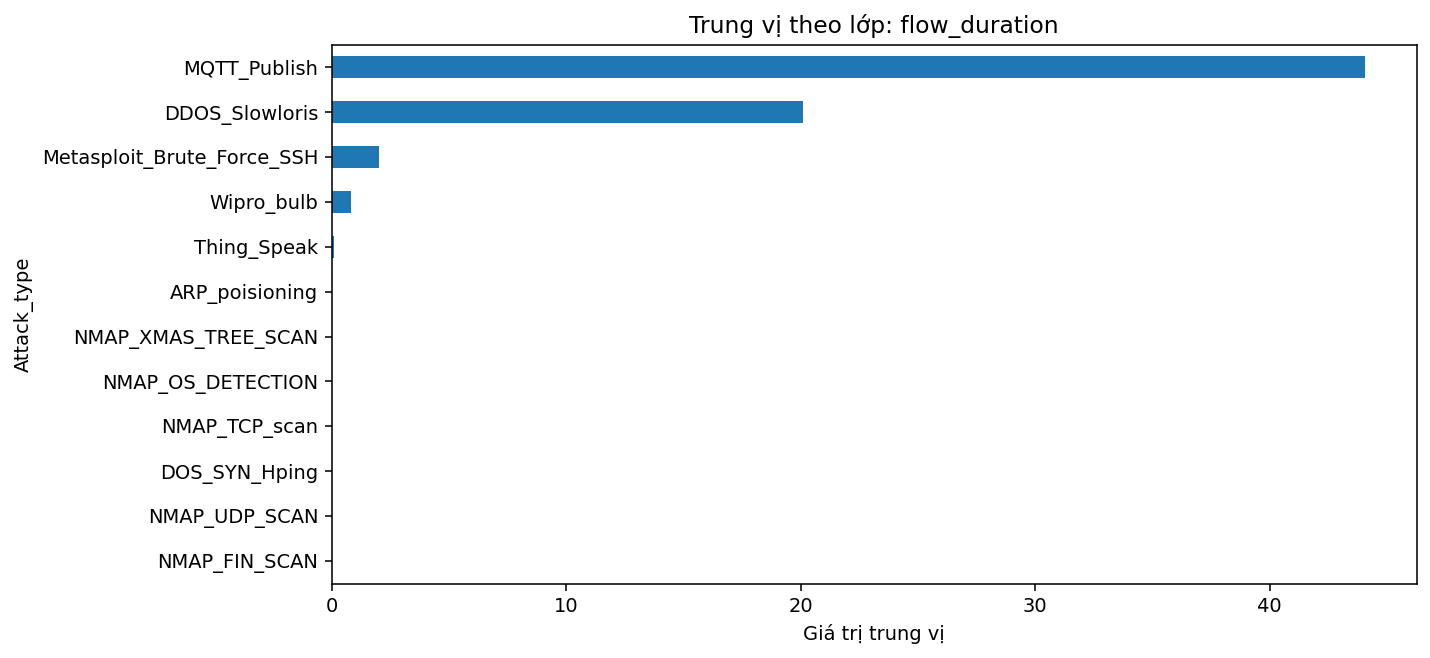

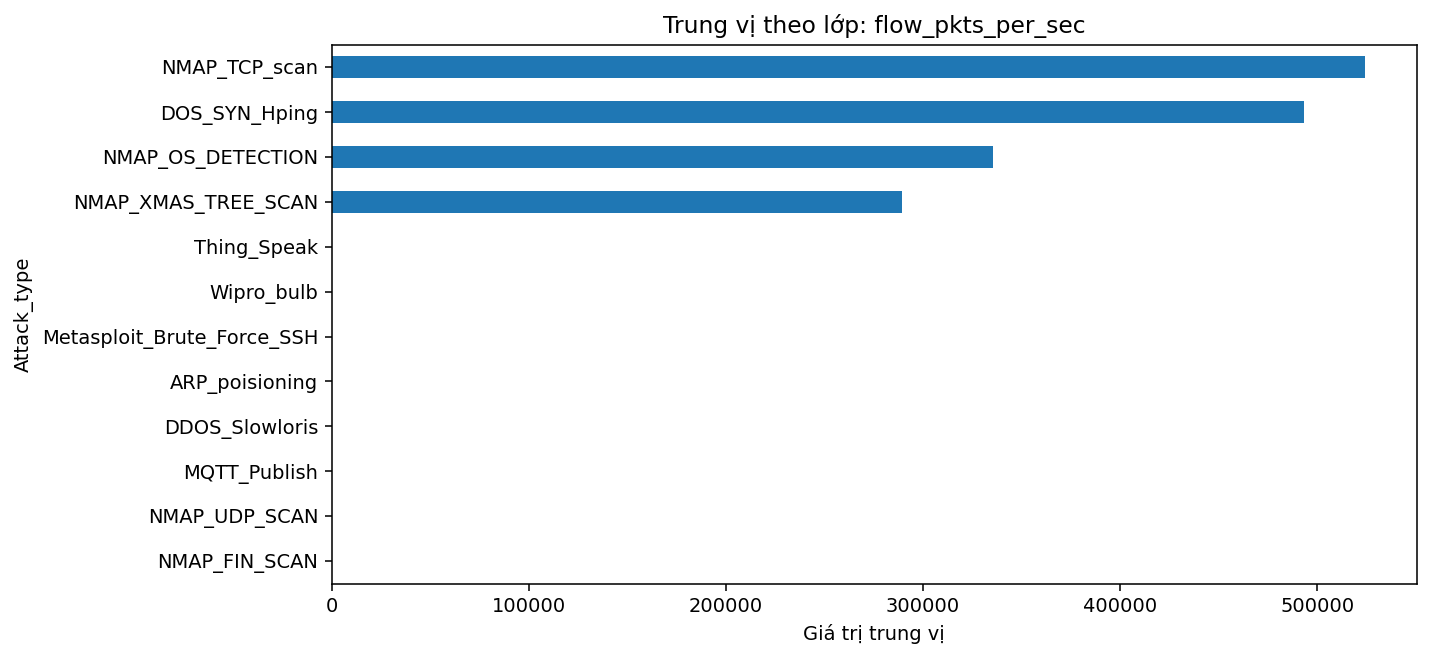

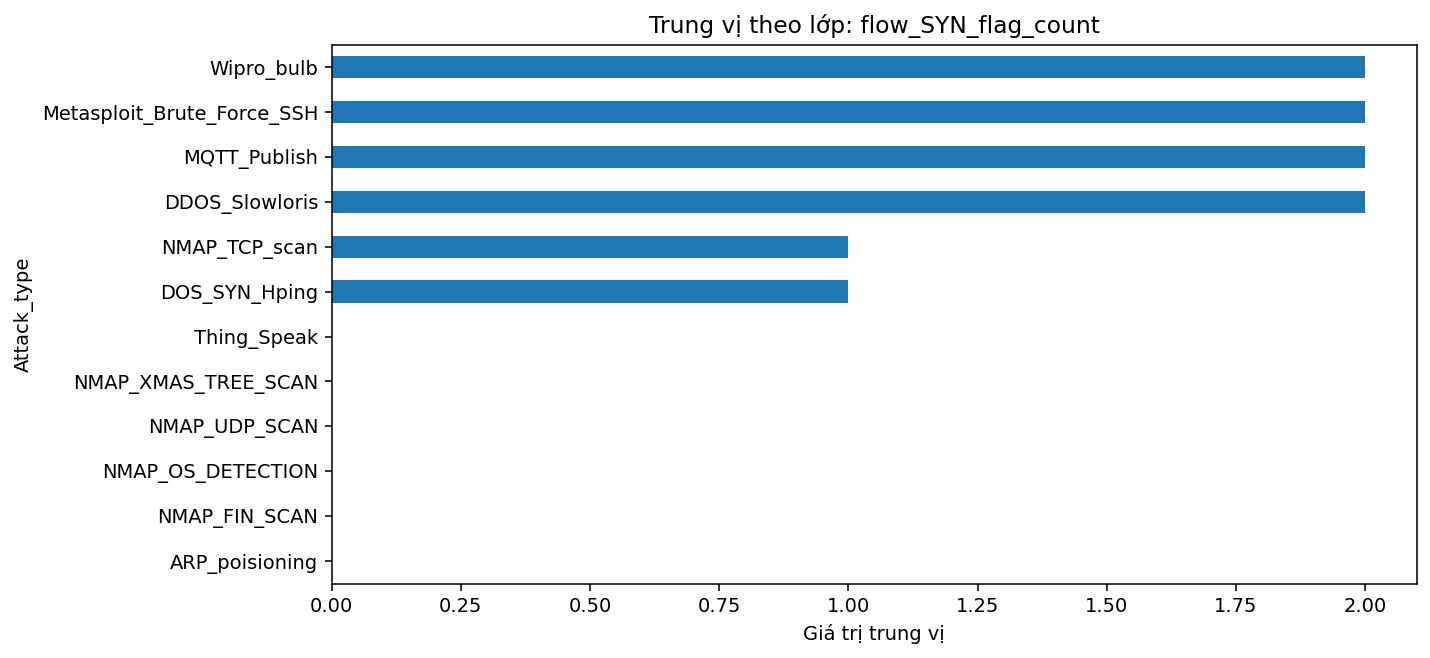

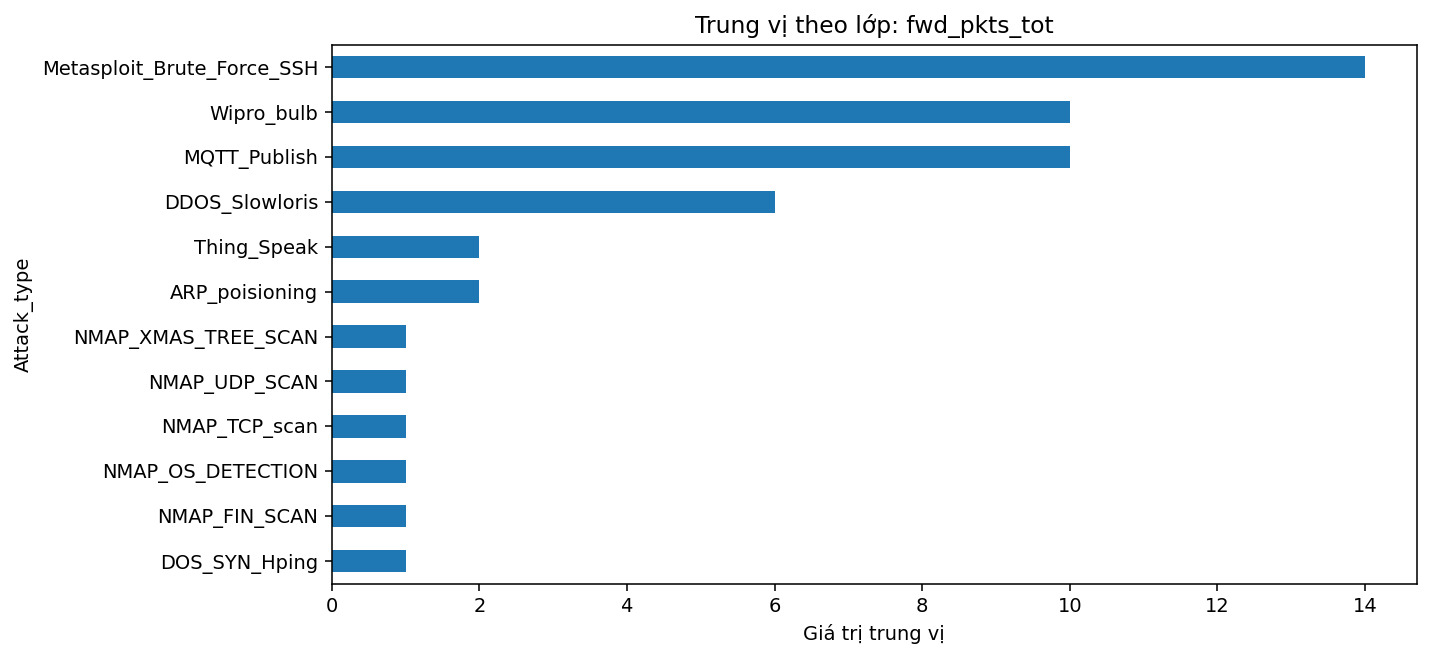

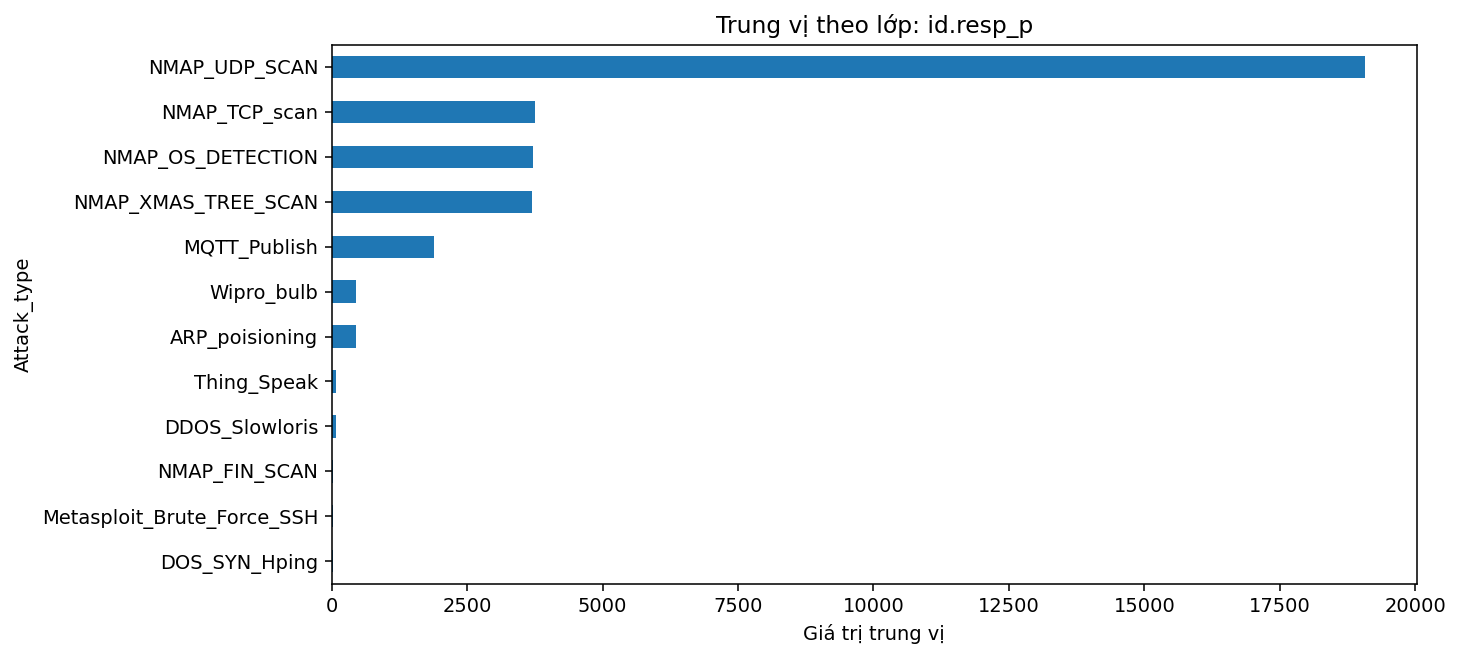

In [17]:
key_features=[c for c in ['flow_duration','flow_pkts_per_sec','flow_SYN_flag_count','fwd_pkts_tot','id.resp_p'] if c in df]
df.groupby(target)[key_features].median().to_csv(TAB/'classwise_feature_medians.csv')
for c in key_features:
    med=df.groupby(target)[c].median().sort_values()
    fig,ax=plt.subplots(figsize=(10,5)); med.plot.barh(ax=ax);ax.set_title('Trung vị theo lớp: '+c);ax.set_xlabel('Giá trị trung vị');fig.savefig(FIG/('06_median_'+c.replace('.','_')+'.png'));plt.close(fig)
display(pd.read_csv(TAB/"classwise_feature_medians.csv").head(12))
for feature in key_features:
    display(Image(filename=str(FIG / ("06_median_" + feature.replace(".", "_") + ".png"))))

### 6. Lưu tóm tắt và kiểm tra kết quả

In [18]:
report={
 'source_file':SRC.name,'sha256':hashlib.sha256(SRC.read_bytes()).hexdigest(),
 'rows':len(df),'columns':len(df.columns),'numeric_columns':len(num.columns),
 'categorical_columns':list(df.select_dtypes(exclude='number').columns),
 'label_count':int(labels.size),'missing_cells':int(df.isna().sum().sum()),
 'infinite_cells':int(np.isinf(num.to_numpy(dtype='float64')).sum()),
 'duplicates_excluding_export_index':duplicates,
 'constant_columns':col_info.loc[col_info['unique']==1,'column'].tolist(),
 'conflicting_feature_groups':conflict_count,'rows_in_conflicting_hash_groups':conflict_rows,
 'largest_class':labels.index[0],'largest_count':int(labels.iloc[0]),
 'smallest_class':labels.index[-1],'smallest_count':int(labels.iloc[-1]),
 'imbalance_ratio':round(float(labels.iloc[0]/labels.iloc[-1]),2),
 'warning':'No rows or columns are modified in the source. Label mapping must be verified with dataset documentation.'}
(OUT/'eda_summary.json').write_text(json.dumps(report,ensure_ascii=False,indent=2),encoding='utf-8')
print(json.dumps(report,ensure_ascii=False,indent=2))
print("Đã lưu:", OUT / "eda_summary.json")

{
  "source_file": "RT_IOT2022.csv",
  "sha256": "956956c09c1764584fa08acd0f6876475626bcedcd6a6b1f8c492c2e9a2089ea",
  "rows": 123117,
  "columns": 85,
  "numeric_columns": 82,
  "categorical_columns": [
    "proto",
    "service",
    "Attack_type"
  ],
  "label_count": 12,
  "missing_cells": 0,
  "infinite_cells": 0,
  "duplicates_excluding_export_index": 5195,
  "constant_columns": [
    "bwd_URG_flag_count"
  ],
  "conflicting_feature_groups": 6,
  "rows_in_conflicting_hash_groups": 128,
  "largest_class": "DOS_SYN_Hping",
  "largest_count": 94659,
  "smallest_class": "NMAP_FIN_SCAN",
  "smallest_count": 28,
  "imbalance_ratio": 3380.68,
  "warning": "No rows or columns are modified in the source. Label mapping must be verified with dataset documentation."
}
Đã lưu: C:\homework\Machine Learning\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\ĐỒ ÁN CUỐI KỲ NHÓM 4\reports\eda_summary.json


C:\Users\Manh Dung\AppData\Local\Temp\ipykernel_35592\4147319451.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  fig,ax=plt.subplots(figsize=(12,7));ax.boxplot(vals,vert=False,labels=ordered,showfliers=False)


,feature,q1,median,q3,iqr,outliers_iqr,outlier_percent
0,flow_duration,0.000001,4.000000e-06,5.000000e-06,4.000000e-06,19171,15.571367
1,flow_pkts_per_sec,149.087077,4.934475e+05,1.048576e+06,1.048427e+06,0,0.000000
2,fwd_pkts_tot,1.000000,1.000000e+00,1.000000e+00,0.000000e+00,17662,14.345704
3,bwd_pkts_tot,1.000000,1.000000e+00,1.000000e+00,0.000000e+00,32364,26.287190
4,flow_SYN_flag_count,1.000000,1.000000e+00,1.000000e+00,0.000000e+00,27362,22.224388
5,payload_bytes_per_second,2580.981105,2.960685e+07,5.592405e+07,5.592147e+07,0,0.000000


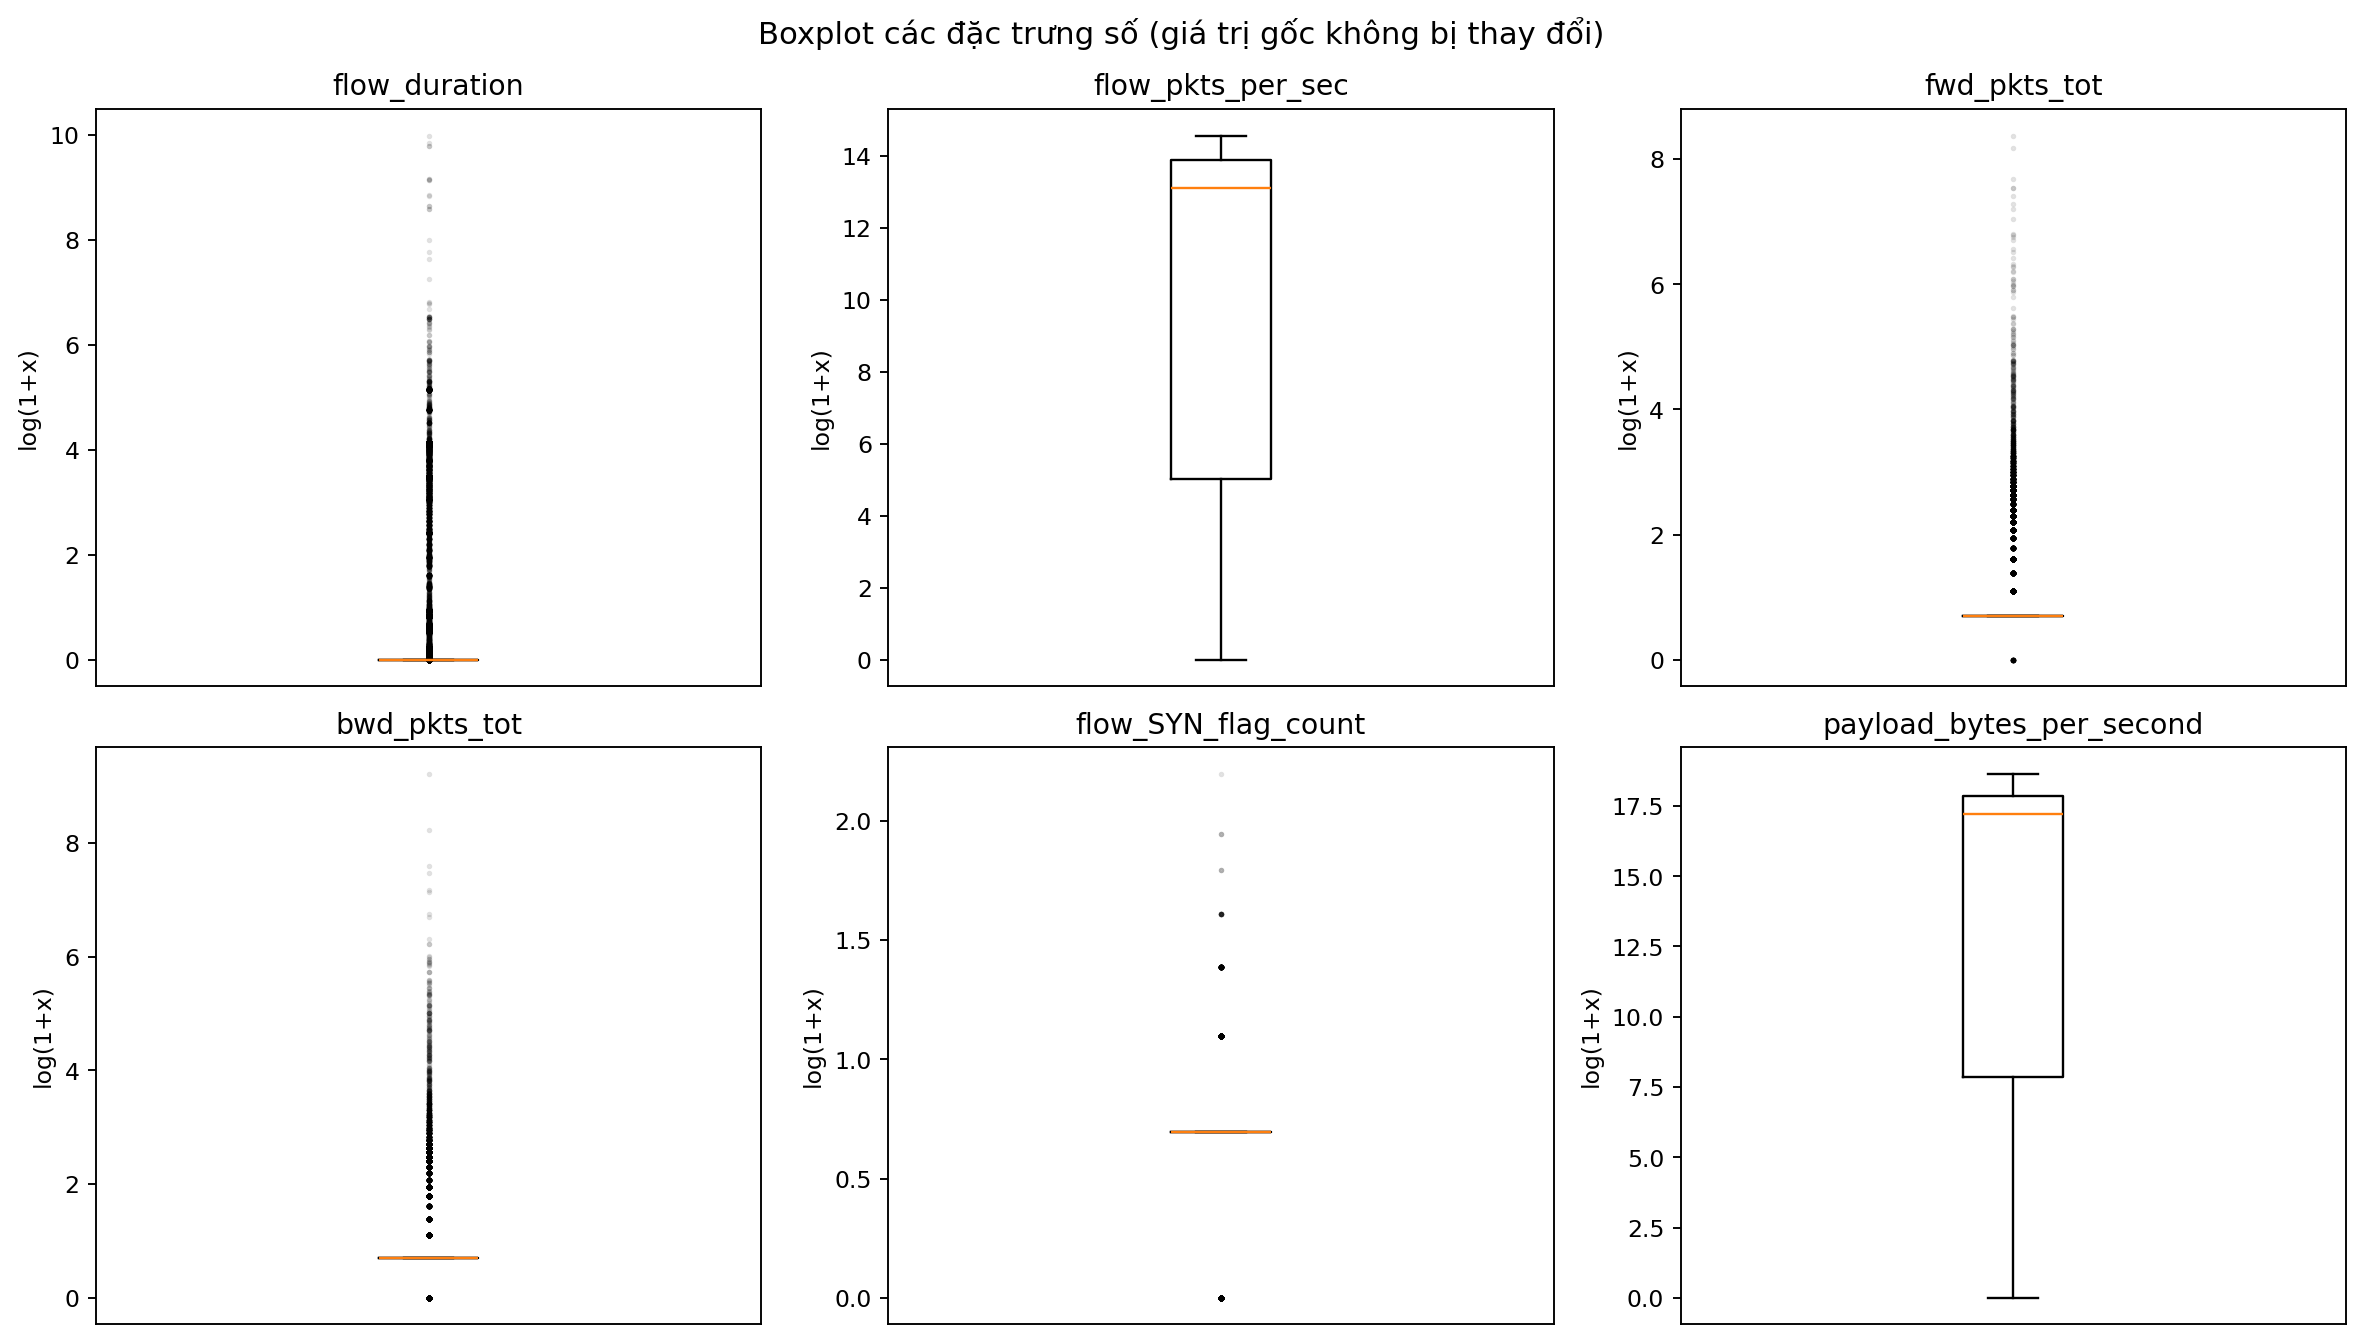

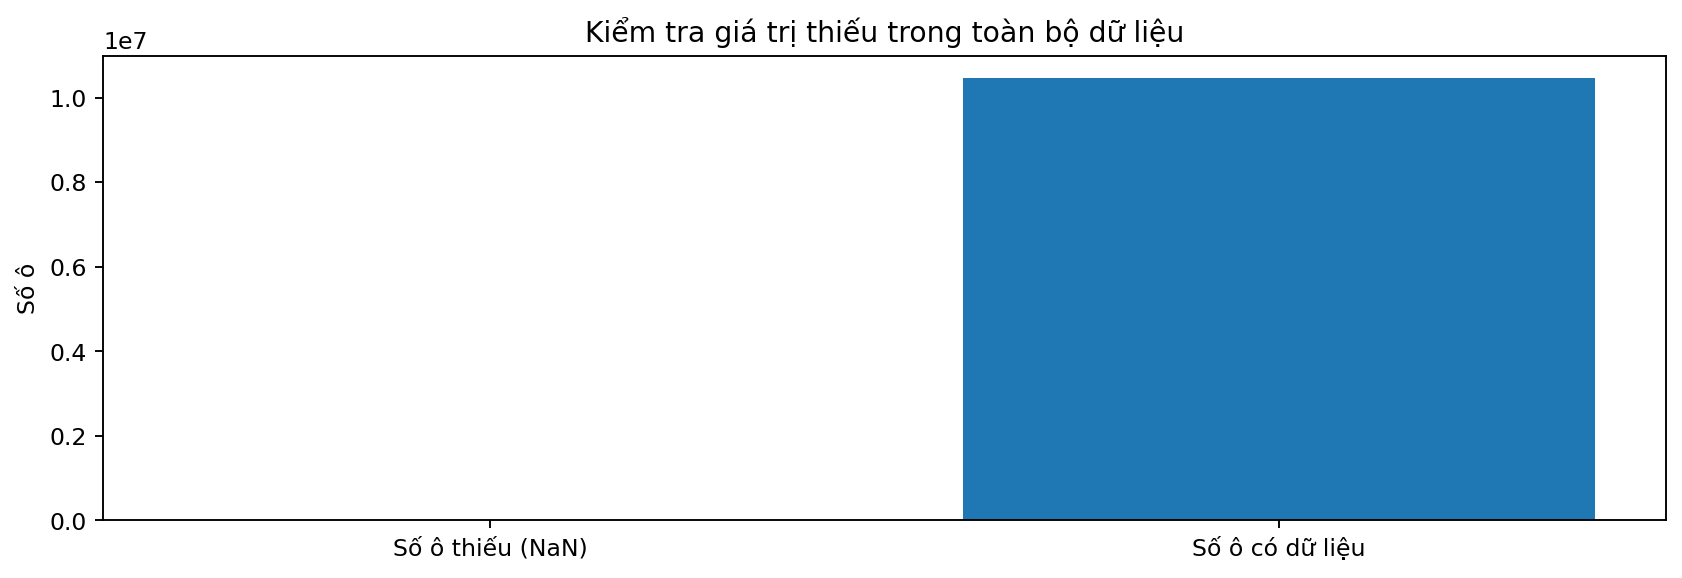

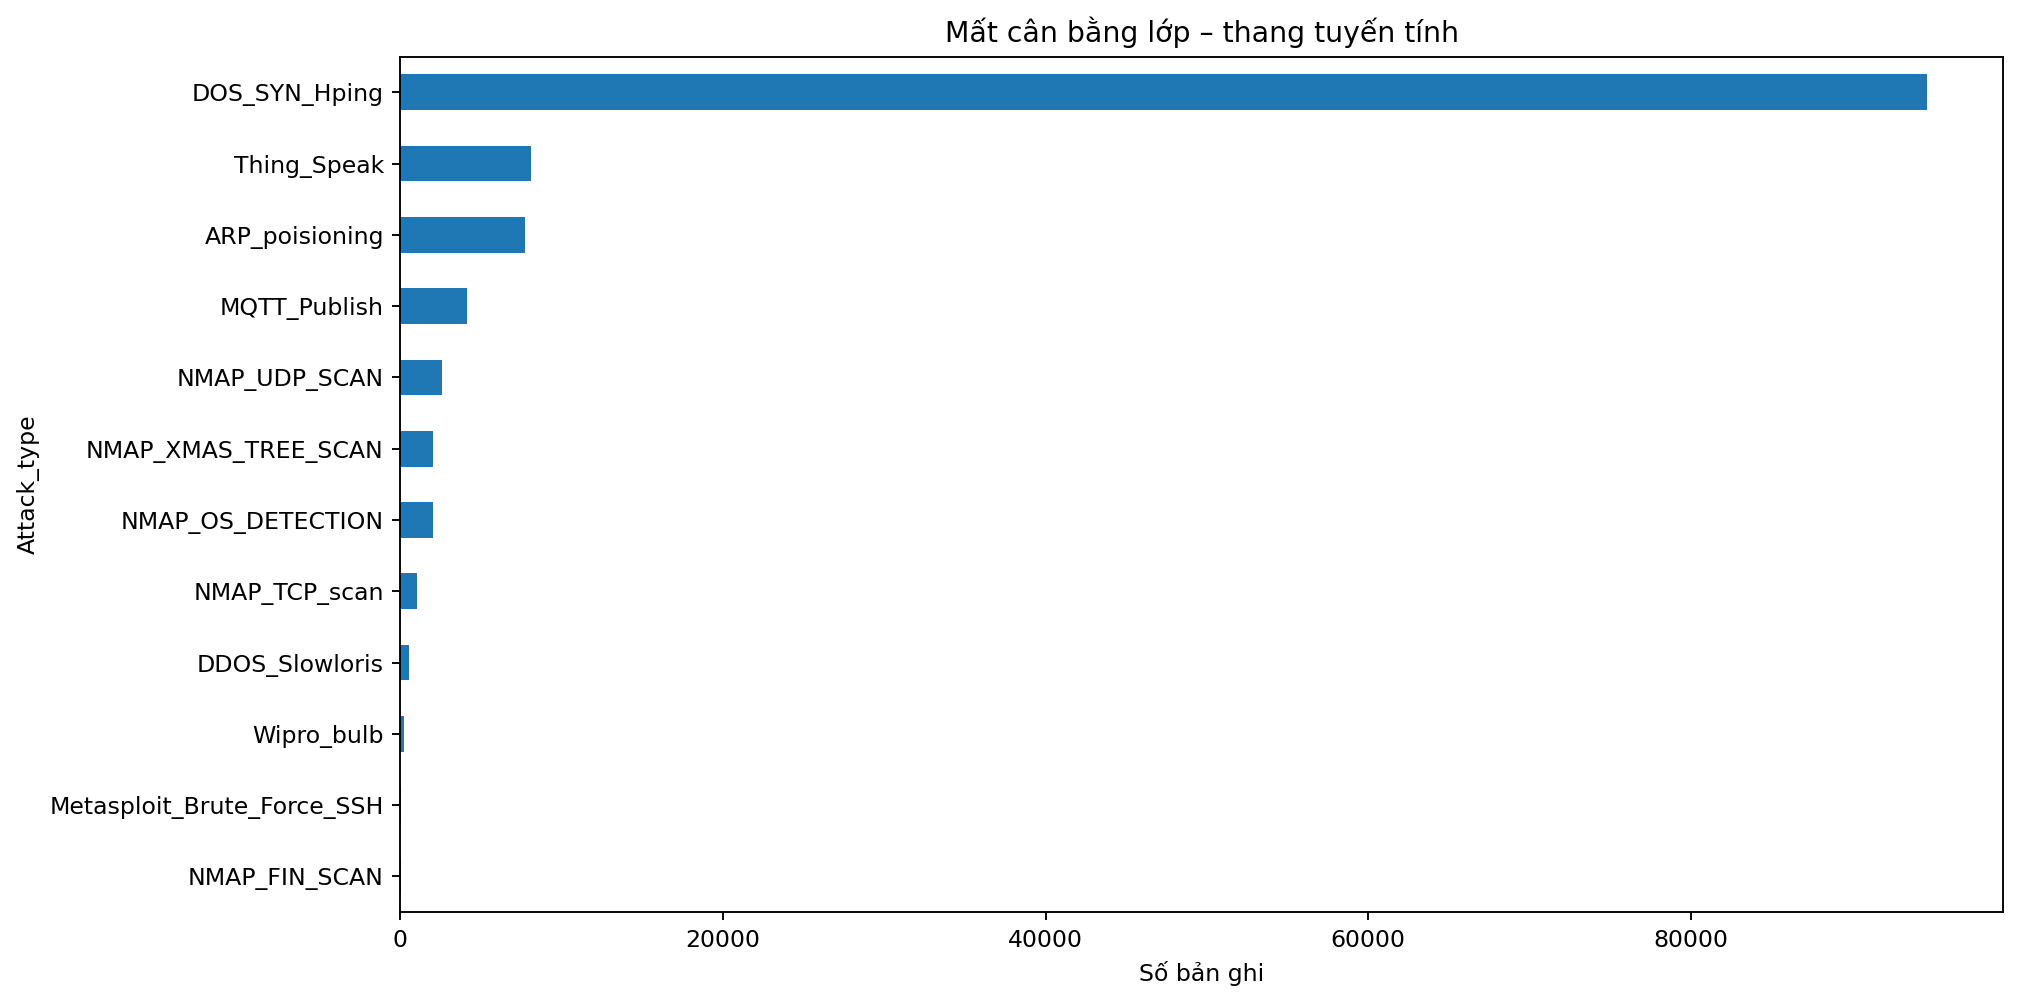

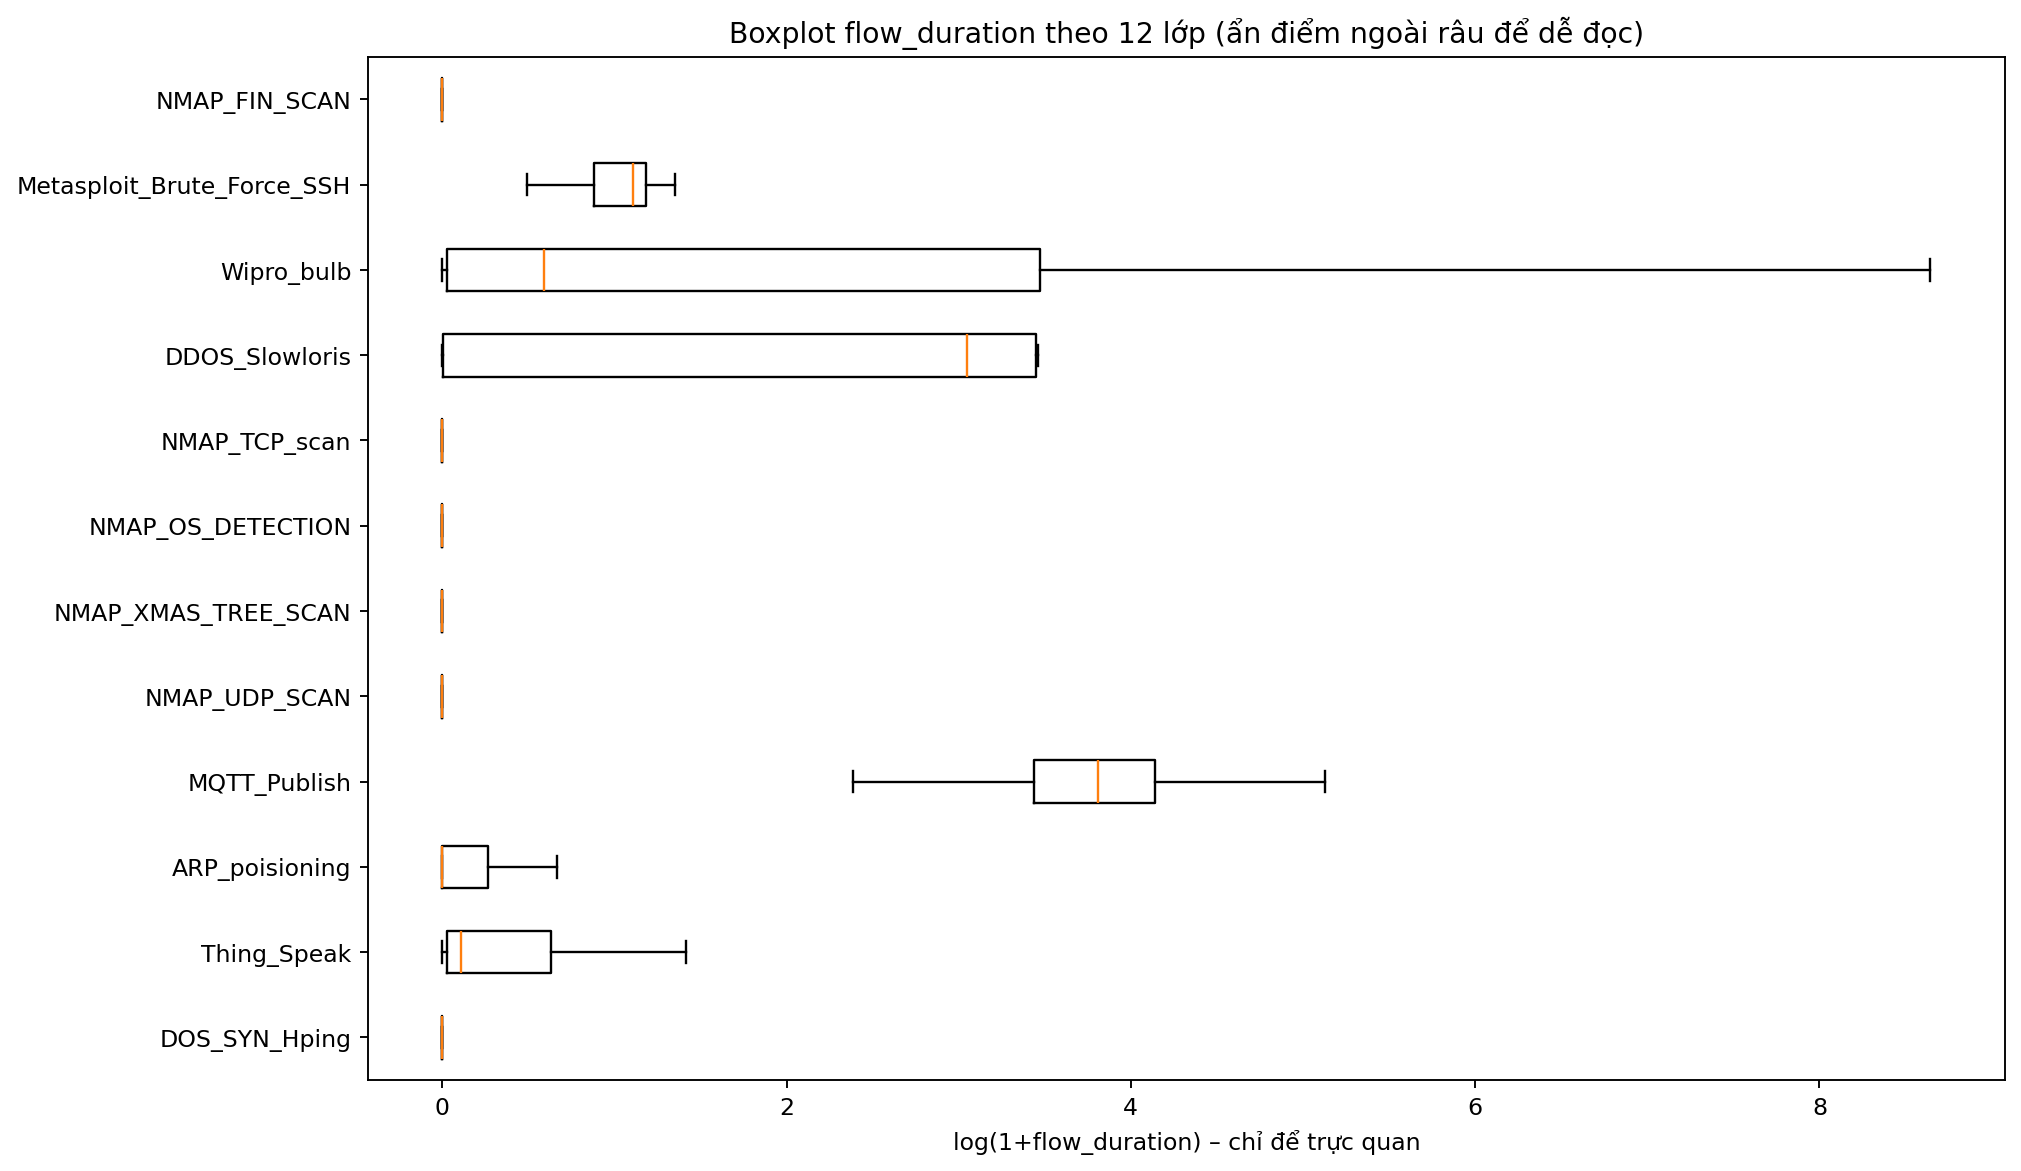

In [19]:
import matplotlib.ticker as mticker
box_features=[c for c in ['flow_duration','flow_pkts_per_sec','fwd_pkts_tot','bwd_pkts_tot','flow_SYN_flag_count','payload_bytes_per_second'] if c in df.columns]
fig,axs=plt.subplots(2,3,figsize=(14,8))
for ax,c in zip(axs.flat,box_features):
    vals=pd.to_numeric(df[c],errors='coerce').replace([np.inf,-np.inf],np.nan).dropna()
    if (vals>=0).all():
        vals=np.log1p(vals); ax.set_ylabel('log(1+x)')
    ax.boxplot(vals,showfliers=True,flierprops={'markersize':1.3,'alpha':0.12})
    ax.set_title(c);ax.set_xticks([])
for ax in list(axs.flat)[len(box_features):]:ax.axis('off')
fig.suptitle('Boxplot các đặc trưng số (giá trị gốc không bị thay đổi)',fontsize=13)
fig.tight_layout();fig.savefig(FIG/'07_boxplots_numeric.png',dpi=170);plt.close(fig)

missing=df.isna().sum().sort_values(ascending=False)
fig,ax=plt.subplots(figsize=(10,3.5));ax.bar(['Số ô thiếu (NaN)','Số ô có dữ liệu'],[int(missing.sum()),int(df.size-missing.sum())]);ax.set_ylabel('Số ô');ax.set_title('Kiểm tra giá trị thiếu trong toàn bộ dữ liệu');fig.tight_layout();fig.savefig(FIG/'08_missing_values.png',dpi=170);plt.close(fig)

fig,ax=plt.subplots(figsize=(12,6));labels.sort_values().plot.barh(ax=ax);ax.set_xlabel('Số bản ghi');ax.set_title('Mất cân bằng lớp – thang tuyến tính');fig.tight_layout();fig.savefig(FIG/'09_class_imbalance_linear.png',dpi=170);plt.close(fig)

compare='flow_duration'
if compare in df:
    ordered=labels.index.tolist()
    vals=[]
    for lab in ordered:
        x=pd.to_numeric(df.loc[df[target]==lab,compare],errors='coerce').dropna()
        vals.append(np.log1p(x.to_numpy()) if (x>=0).all() else x.to_numpy())
    fig,ax=plt.subplots(figsize=(12,7));ax.boxplot(vals,vert=False,labels=ordered,showfliers=False)
    ax.set_xlabel('log(1+flow_duration) – chỉ để trực quan');ax.set_title('Boxplot flow_duration theo 12 lớp (ẩn điểm ngoài râu để dễ đọc)');fig.tight_layout();fig.savefig(FIG/'10_boxplot_duration_by_class.png',dpi=170);plt.close(fig)

# Bảng outlier theo quy tắc IQR – chỉ thống kê, không xóa
outlier_rows=[]
for c in box_features:
    x=pd.to_numeric(df[c],errors='coerce').replace([np.inf,-np.inf],np.nan).dropna()
    q1,q3=x.quantile([.25,.75]);iqr=q3-q1
    n=int(((x<q1-1.5*iqr)|(x>q3+1.5*iqr)).sum())
    outlier_rows.append({'feature':c,'q1':q1,'median':x.median(),'q3':q3,'iqr':iqr,'outliers_iqr':n,'outlier_percent':100*n/len(x)})
outlier_table=pd.DataFrame(outlier_rows)
outlier_table.to_csv(TAB/'outlier_iqr_summary.csv',index=False)
display(outlier_table)
from IPython.display import Image
for name in ['07_boxplots_numeric.png','08_missing_values.png','09_class_imbalance_linear.png','10_boxplot_duration_by_class.png']:
    display(Image(filename=str(FIG/name)))

,label,count,percentage
0,DOS_SYN_Hping,94659,76.885402
1,Thing_Speak,8108,6.585606
2,ARP_poisioning,7750,6.294825
3,MQTT_Publish,4146,3.367528
4,NMAP_UDP_SCAN,2590,2.103690
5,NMAP_XMAS_TREE_SCAN,2010,1.632593
6,NMAP_OS_DETECTION,2000,1.624471
7,NMAP_TCP_scan,1002,0.813860
8,DDOS_Slowloris,534,0.433734
9,Wipro_bulb,253,0.205496


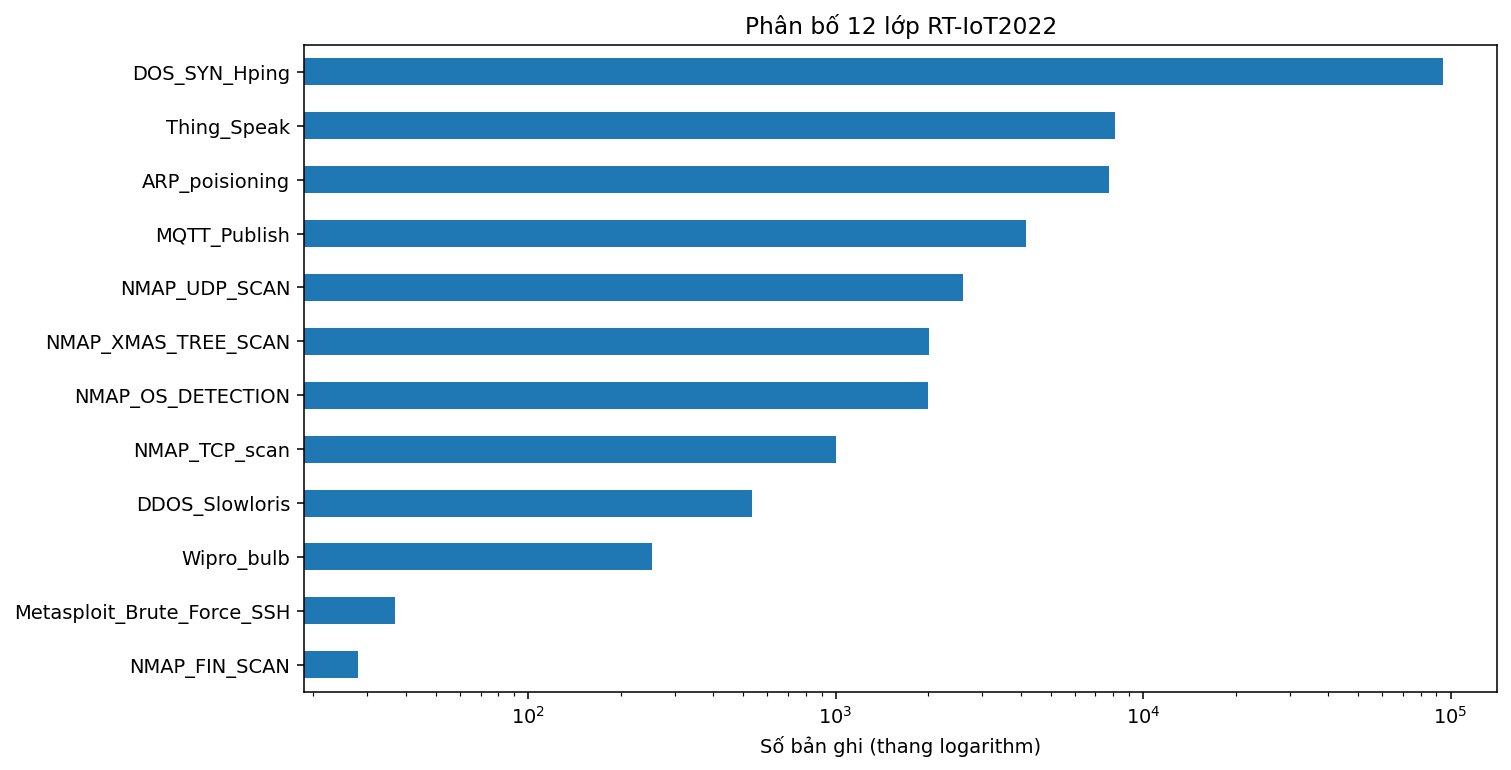

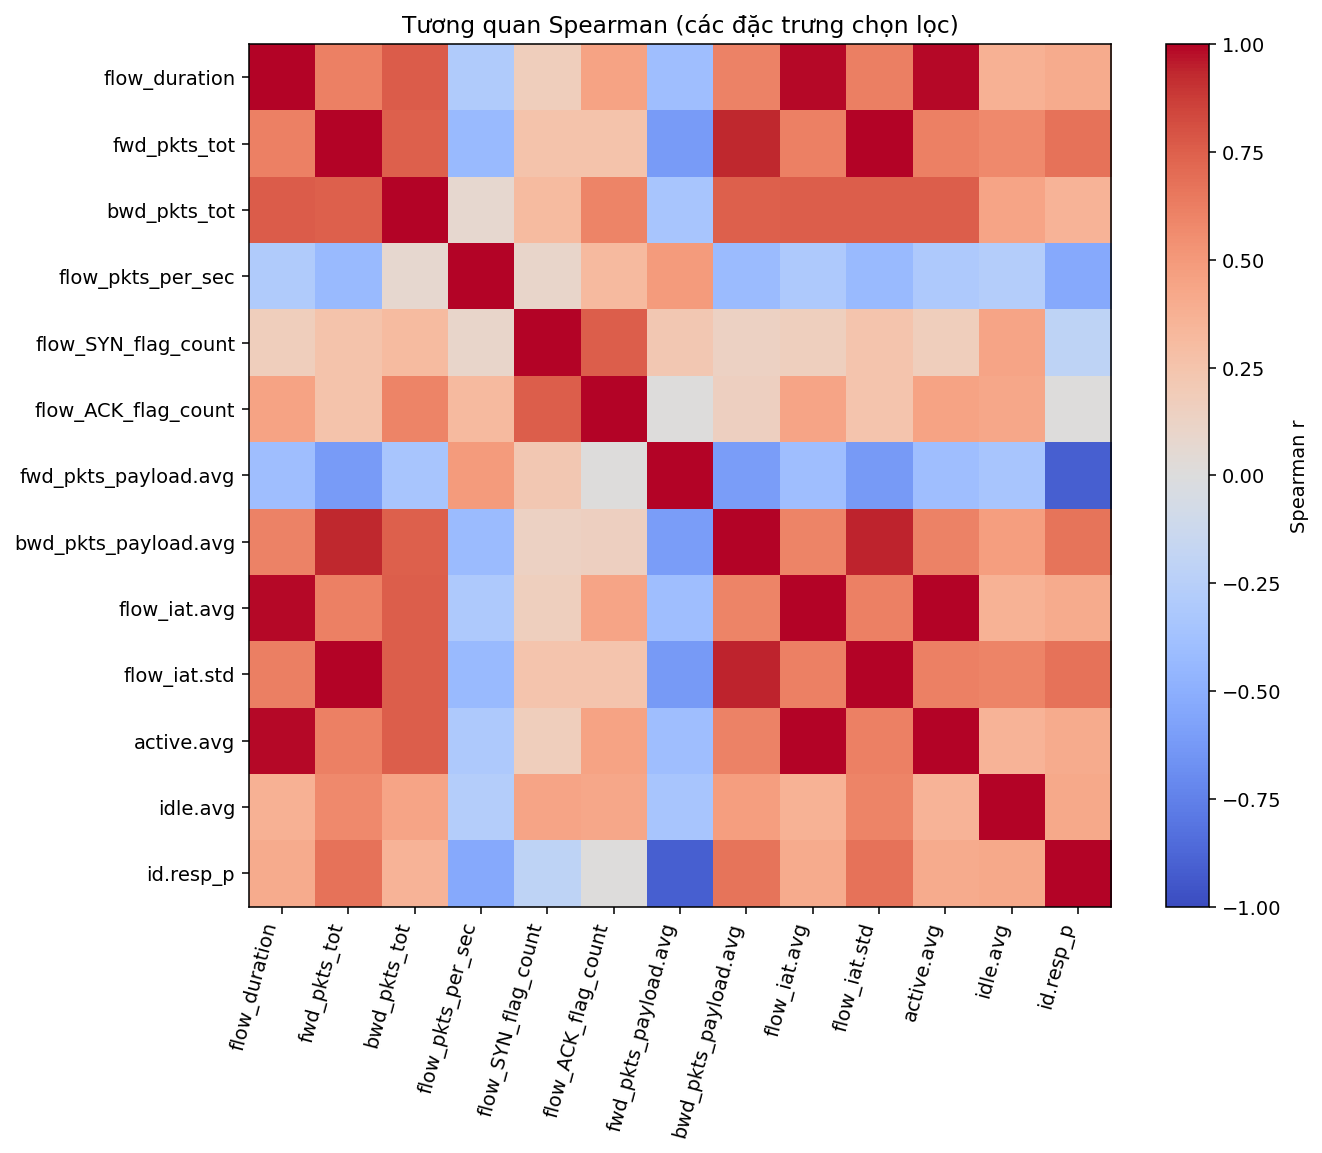

In [20]:
from IPython.display import Image, display
display(pd.read_csv(TAB/'class_distribution.csv'))
display(Image(filename=str(FIG/'01_class_distribution_log.png')))
display(Image(filename=str(FIG/'05_spearman_heatmap.png')))